# #204 Track A Gate A v5 — data-build audit

This executed notebook orchestrates the canonical outcome-unexposed construction.
It uses the reusable adapter in `unified_model.gate_a`; it never reads result,
winning-SP, final-SP, or target-update values.  With the three explicit source
environment variables it rebuilds the full immutable 344/75 panel; otherwise it
runs the committed bounded fixture path for portable review.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
PACKAGE = ROOT / 'results/bj204_gate_a_preoutcome_v5'
SOURCE = ROOT / 'results/bj203_causal_tensor_v2'
FIXTURES = ROOT / 'tests/fixtures/bj204'
assert PACKAGE.is_dir() and SOURCE.is_dir() and FIXTURES.is_dir()
print('canonical package:', PACKAGE.name)
from unified_model.contract import OUTCOME_ORDER
from unified_model.gate_a import verify_package


canonical package: bj204_gate_a_preoutcome_v5


In [2]:
verification = verify_package(PACKAGE)
card = json.loads((PACKAGE / 'freeze_card.json').read_text())
source_inventory = pd.DataFrame([
    {'name': key, 'value': value}
    for key, value in card['source'].items()
    if key.endswith('sha256') or key.endswith('source')
])
assert card['source']['labels_opened'] is False
assert tuple(card['schema']['outcome_axis']) == OUTCOME_ORDER
display(source_inventory)
verification

,name,value
0,history_proxy_sha256,867e11452306c29e7b64b97af82f730ab0d96f7519d995...
1,history_proxy_source,data/beidan_history.db
2,inference_manifest_sha256,c915c6e628b4ebfe389ab31fd3709561440892ede711f2...
3,official_3sp_identity_sha256,e7256d96a34c2f41ede349c87b9cd1efc7a61b104657a6...
4,official_3sp_identity_source,data/raw/beidan_full_3sp.csv
5,p_close_bridge_sha256,48d73b868235a78d73ea2587d5a2cd9094a861b605bfcd...
6,p_close_bridge_source,data/beidan_features.db


{'contract_version': 'bj204-market-anchored-model-gate-a-v5',
 'files': 23,
 'status': 'PASS'}

In [3]:
splits = pd.read_csv(PACKAGE / 'split_manifest.csv', dtype={'issue': str})
registry = pd.read_csv(PACKAGE / 'common_issue_registry.csv', dtype={'issue': str})
true_issue_match_census = registry.groupby(
    ['role', 'source_grade', 'year'], sort=True
).agg(
    issues=('issue', 'nunique'),
    matches=('match_idx', 'size'),
    complete_market_rows=('market_proxy_complete', 'sum'),
).reset_index()
assert true_issue_match_census.loc[
    true_issue_match_census.role.eq('DEVELOPMENT_CV'), 'issues'
].sum() == 344
assert true_issue_match_census.loc[
    true_issue_match_census.role.eq('RETROSPECTIVE_TEST_LOCKED'), 'issues'
].sum() == 75
assert true_issue_match_census.loc[
    true_issue_match_census.role.eq('DEVELOPMENT_CV'), 'matches'
].sum() == 102245
assert true_issue_match_census.loc[
    true_issue_match_census.role.eq('RETROSPECTIVE_TEST_LOCKED'), 'matches'
].sum() == 16990
assert splits.loc[splits.role.eq('DEVELOPMENT_CV'), 'issue'].nunique() == 344
assert splits.loc[splits.role.eq('RETROSPECTIVE_TEST_LOCKED'), 'issue'].nunique() == 75
true_issue_match_census

,role,source_grade,year,issues,matches,complete_market_rows
0,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2019,55,17694,17565
1,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2020,44,12033,11815
2,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2021,58,18881,18624
3,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2022,58,16787,16579
4,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2023,55,15759,15595
5,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2024,59,16236,16057
6,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2025,15,4855,4794
7,RETROSPECTIVE_TEST_LOCKED,RETROSPECTIVE_PROXY,2025,42,11382,11366
8,RETROSPECTIVE_TEST_LOCKED,RETROSPECTIVE_PROXY,2026,33,5608,5602


In [4]:
test_identity = pd.read_csv(PACKAGE / 'test_identity_reconciliation.csv', dtype={'issue': str})
dev_target_identity = pd.read_csv(PACKAGE / 'development_target_identity_reconciliation.csv', dtype={'issue': str})
duplicate_resolution = pd.read_csv(PACKAGE / 'pclose_duplicate_resolution.csv', dtype={'source_issue': str})
reconciliation = pd.DataFrame([
    {'scope': 'locked test identity', 'rows': len(test_identity), 'matched': int(test_identity.official_target_identity_available.sum()), 'unmatched': int((~test_identity.official_target_identity_available).sum())},
    {'scope': '25041/25042 development identity', 'rows': len(dev_target_identity), 'matched': int(dev_target_identity.official_target_identity_available.sum()), 'unmatched': int((~dev_target_identity.official_target_identity_available).sum())},
    {'scope': 'p_close duplicate issue+match keys', 'rows': len(duplicate_resolution), 'matched': int(duplicate_resolution.canonical_selected.sum()), 'unmatched': int((~duplicate_resolution.canonical_selected).sum())},
])
reconciliation_reason_census = pd.concat([
    test_identity.assign(scope='locked_test').groupby(['scope', 'target_identity_reason'], sort=True).size().rename('rows').reset_index(),
    dev_target_identity.assign(scope='development_25041_25042').groupby(['scope', 'target_identity_reason'], sort=True).size().rename('rows').reset_index(),
    duplicate_resolution.assign(scope='pclose_duplicate').groupby(['scope', 'resolution'], sort=True).size().rename('rows').reset_index().rename(columns={'resolution': 'target_identity_reason'}),
], ignore_index=True)
assert reconciliation.loc[0, 'rows'] == 16990 and reconciliation.loc[0, 'matched'] == 16853
assert reconciliation.loc[1, 'rows'] == 1024 and reconciliation.loc[1, 'matched'] == 1021
assert set(duplicate_resolution.pclose_match_uid.astype(str)) == {'1163202', '1917703', '2223802'}
assert duplicate_resolution.values_equal_within_issue_match_uid.all()
assert int(duplicate_resolution.canonical_selected.sum()) == 5
display(reconciliation)
display(duplicate_resolution)
reconciliation_reason_census

,scope,rows,matched,unmatched
0,locked test identity,16990,16853,137
1,25041/25042 development identity,1024,1021,3
2,p_close duplicate issue+match keys,6,5,1


,pclose_match_uid,source_issue,source_row_ordinal,p_close_3,p_close_1,p_close_0,beidan_hcap,source_rows_for_match_uid,source_issue_count,rows_for_issue_match_uid,probability_values_equal_for_match_uid,handicap_values_equal_for_match_uid,values_equal_within_issue_match_uid,issue_match_uid_resolves,canonical_selected,resolution
0,1163202,151004,32313,0.389435,0.318007,0.292558,0,2,2,1,True,True,True,True,True,ISSUE_PLUS_MATCH_UID
1,1163202,160201,36733,0.389435,0.318007,0.292558,0,2,2,1,True,True,True,True,True,ISSUE_PLUS_MATCH_UID
2,1917703,20104,114696,0.350258,0.251329,0.398412,0,2,1,2,True,True,True,False,True,EQUAL_VALUES_FIRST_SOURCE_ROW_WITHIN_ISSUE
3,1917703,20104,115022,0.350258,0.251329,0.398412,0,2,1,2,True,True,True,False,False,EQUAL_VALUES_FIRST_SOURCE_ROW_WITHIN_ISSUE
4,2223802,22124,154007,0.463027,0.283471,0.253501,0,2,2,1,True,True,True,True,True,ISSUE_PLUS_MATCH_UID
5,2223802,22125,154063,0.463027,0.283471,0.253501,0,2,2,1,True,True,True,True,True,ISSUE_PLUS_MATCH_UID


,scope,target_identity_reason,rows
0,locked_test,HISTORY_ONLY_NO_OFFICIAL_3SP_TARGET,137
1,locked_test,MATCHED_OFFICIAL_3SP_TARGET_NOT_OPENED,16853
2,development_25041_25042,DEVELOPMENT_INFERENCE_IDENTITY_WITHOUT_OFFICIA...,3
3,development_25041_25042,MATCHED_OFFICIAL_3SP_TARGET_NOT_OPENED,1021
4,pclose_duplicate,EQUAL_VALUES_FIRST_SOURCE_ROW_WITHIN_ISSUE,2
5,pclose_duplicate,ISSUE_PLUS_MATCH_UID,4


In [5]:
import os
from unified_model.contract import OUTCOME_ORDER
from unified_model.gate_a import _common_adapter, _read_full_3sp_identity, _read_history_rows, _validate_source

identity, _ = _validate_source(SOURCE)
full_inputs = {name: os.environ.get(name) for name in ('BJ204_HISTORY_SOURCE', 'BJ204_FULL_3SP_IDENTITY_SOURCE', 'BJ204_PCLOSE_SOURCE')}
if all(full_inputs.values()):
    # Explicit, read-only full replay: no parent-worktree discovery.
    construction_history = _read_history_rows(Path(full_inputs['BJ204_HISTORY_SOURCE']), ((25043, 25125), (26011, 26049)))
    construction_full = _read_full_3sp_identity(Path(full_inputs['BJ204_FULL_3SP_IDENTITY_SOURCE']))
    constructed_features, constructed_masks, constructed_registry, construction_coverage, construction_duplicates = _common_adapter(
        SOURCE, identity, construction_history, construction_full, Path(full_inputs['BJ204_PCLOSE_SOURCE'])
    )
    construction_mode = 'FULL_EXPLICIT_IMMUTABLE_SOURCES'
    expected_constructed_cells = 357705
else:
    # Default detached execution uses the committed bounded fixture mechanism.
    construction_identity = identity.loc[identity.issue.astype(str).eq('190101') & identity.match_idx.isin([1, 2])].copy()
    construction_history = _read_history_rows(FIXTURES / 'history_proxy.csv', ((25043, 25043),))
    construction_full = _read_full_3sp_identity(FIXTURES / 'full_3sp_identity.csv')
    constructed_features, constructed_masks, constructed_registry, construction_coverage, construction_duplicates = _common_adapter(
        SOURCE, construction_identity, construction_history, construction_full, FIXTURES / 'pclose_proxy.csv', strict_census=False
    )
    construction_mode = 'BOUNDED_COMMITTED_FIXTURES'
    expected_constructed_cells = 12
assert len(constructed_features) == expected_constructed_cells
assert constructed_features.groupby(['issue', 'match_idx']).outcome_code.agg(tuple).map(lambda value: value == OUTCOME_ORDER).all()
print('adapter construction mode:', construction_mode, 'constructed common M×3 cells:', len(constructed_features))
construction_coverage

adapter construction mode: FULL_EXPLICIT_IMMUTABLE_SOURCES constructed common M×3 cells: 357705


,role,source_grade,year,issues,matches,complete_market_rows,fallback_no_bet_rows,common_schema_coverage
0,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2019,55,17694,17565,129,0.992709
1,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2020,44,12033,11815,218,0.981883
2,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2021,58,18881,18624,257,0.986388
3,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2022,58,16787,16579,208,0.987609
4,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2023,55,15759,15595,164,0.989593
5,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2024,59,16236,16057,179,0.988975
6,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2025,15,4855,4794,61,0.987436
7,RETROSPECTIVE_TEST_LOCKED,RETROSPECTIVE_PROXY,2025,42,11382,11366,16,0.998594
8,RETROSPECTIVE_TEST_LOCKED,RETROSPECTIVE_PROXY,2026,33,5608,5602,6,0.998930


In [6]:
from unified_model.gate_a import load_common_issue

dev_values, dev_masks, names = load_common_issue(PACKAGE, '190202')
test_values, test_masks, test_names = load_common_issue(PACKAGE, '25043')
assert names == test_names and dev_values.shape[1:] == test_values.shape[1:] == (3, len(names))
canonical_axis_evidence = pd.DataFrame([
    {'split': 'development', 'issue': '190202', 'tensor_shape': dev_values.shape, 'outcome_axis': '/'.join(OUTCOME_ORDER), 'mask_true_rate': float(dev_masks.mean()), 'source_grade': 'RETROSPECTIVE_PROXY_PCLOSE'},
    {'split': 'locked test', 'issue': '25043', 'tensor_shape': test_values.shape, 'outcome_axis': '/'.join(OUTCOME_ORDER), 'mask_true_rate': float(test_masks.mean()), 'source_grade': 'RETROSPECTIVE_PROXY'},
])
assert np.isfinite(dev_values[:, :, names.index('market_probability')]).all()
assert np.isfinite(test_values[:, :, names.index('market_probability')]).all()
market_feature = names.index('market_probability')
code_to_value_evidence = pd.DataFrame({
    'split': ['development'] * 3 + ['locked test'] * 3,
    'outcome_code': list(OUTCOME_ORDER) * 2,
    'first_match_market_probability': np.concatenate([
        dev_values[0, :, market_feature], test_values[0, :, market_feature],
    ]),
})
display(canonical_axis_evidence)
code_to_value_evidence

,split,issue,tensor_shape,outcome_axis,mask_true_rate,source_grade
0,development,190202,"(357, 3, 6)",3/1/0,0.843137,RETROSPECTIVE_PROXY_PCLOSE
1,locked test,25043,"(493, 3, 6)",3/1/0,0.833333,RETROSPECTIVE_PROXY


,split,outcome_code,first_match_market_probability
0,development,3,0.575068
1,development,1,0.254137
2,development,0,0.170795
3,locked test,3,0.334745
4,locked test,1,0.283087
5,locked test,0,0.382168


In [7]:
common_cell_features = pd.read_parquet(PACKAGE / 'common_cell_features.parquet')
common_cell_masks = pd.read_parquet(PACKAGE / 'common_cell_masks.parquet')
coverage = pd.read_csv(PACKAGE / 'common_schema_coverage_by_period.csv')
field_coverage = pd.read_csv(PACKAGE / 'common_schema_field_coverage.csv', dtype={'outcome_code': str})
probability_validity = pd.read_csv(PACKAGE / 'common_probability_validity.csv')
assert len(common_cell_features) == 357705
assert coverage.matches.sum() == 102245 + 16990
assert field_coverage.outcome_code.isin(OUTCOME_ORDER).all()
field_coverage['outcome_code'] = pd.Categorical(
    field_coverage.outcome_code, categories=list(OUTCOME_ORDER), ordered=True,
)
probability_validity_by_year = probability_validity.sort_values(['role', 'year']).reset_index(drop=True)
field_outcome_completeness = field_coverage.sort_values(['role', 'year', 'outcome_code', 'feature']).reset_index(drop=True)
assert tuple(field_outcome_completeness.outcome_code.cat.categories) == OUTCOME_ORDER
assert probability_validity_by_year.market_triplet_valid_rows.sum() == 101029 + 16968
assert probability_validity_by_year.fallback_no_bet_rows.sum() == 1216 + 22
if construction_mode == 'FULL_EXPLICIT_IMMUTABLE_SOURCES':
    pd.testing.assert_frame_equal(
        constructed_features.reset_index(drop=True), common_cell_features.reset_index(drop=True), check_dtype=False
    )
    pd.testing.assert_frame_equal(
        constructed_masks.reset_index(drop=True), common_cell_masks.reset_index(drop=True), check_dtype=False
    )
    print('full-source adapter rebuild: byte-identical table values and order')
display(probability_validity_by_year)
field_outcome_completeness

full-source adapter rebuild: byte-identical table values and order


,role,source_grade,year,matches,market_triplet_valid_rows,fallback_no_bet_rows,handicap_complete_rows,predicted_sp_input_complete_rows
0,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2019,17694,17565,129,17565,1229
1,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2020,12033,11815,218,11815,1134
2,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2021,18881,18624,257,18624,1598
3,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2022,16787,16579,208,16579,1125
4,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2023,15759,15595,164,15595,1126
5,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2024,16236,16057,179,16057,1357
6,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2025,4855,4794,61,4794,269
7,RETROSPECTIVE_TEST_LOCKED,RETROSPECTIVE_PROXY,2025,11382,11366,16,11382,0
8,RETROSPECTIVE_TEST_LOCKED,RETROSPECTIVE_PROXY,2026,5608,5602,6,5608,0


,role,source_grade,year,outcome_code,feature,cells,available_cells,missing_cells,coverage
0,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2019,3,market_probability,17694,17565,129,0.992709
1,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2019,3,market_proxy_complete,17694,17694,0,1.000000
2,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2019,3,native_handicap_line,17694,17565,129,0.992709
3,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2019,3,predicted_final_sp_input,17694,1229,16465,0.069459
4,DEVELOPMENT_CV,RETROSPECTIVE_PROXY_PCLOSE,2019,3,source_is_average_eu,17694,17694,0,1.000000
...,...,...,...,...,...,...,...,...,...
157,RETROSPECTIVE_TEST_LOCKED,RETROSPECTIVE_PROXY,2026,0,market_proxy_complete,5608,5608,0,1.000000
158,RETROSPECTIVE_TEST_LOCKED,RETROSPECTIVE_PROXY,2026,0,native_handicap_line,5608,5608,0,1.000000
159,RETROSPECTIVE_TEST_LOCKED,RETROSPECTIVE_PROXY,2026,0,predicted_final_sp_input,5608,0,5608,0.000000
160,RETROSPECTIVE_TEST_LOCKED,RETROSPECTIVE_PROXY,2026,0,source_is_average_eu,5608,5608,0,1.000000


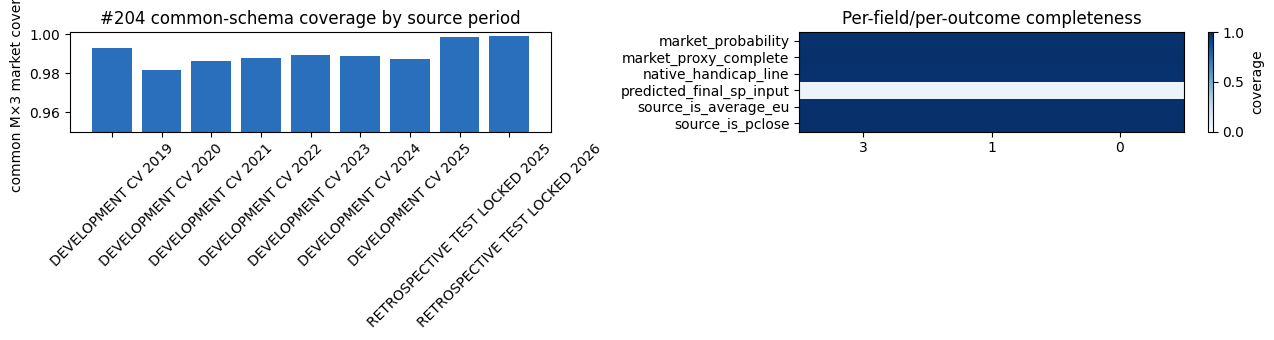

In [8]:
plot = coverage.assign(period=lambda x: x.role.str.replace('_', ' ') + ' ' + x.year.astype(str))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].bar(plot.period, plot.common_schema_coverage, color=['#2a6fbb'] * len(plot))
axes[0].set_ylim(0.95, 1.001); axes[0].set_ylabel('common M×3 market coverage'); axes[0].tick_params(axis='x', rotation=45)
axes[0].set_title('#204 common-schema coverage by source period')
heat = field_outcome_completeness.pivot_table(index='feature', columns='outcome_code', values='coverage', aggfunc='mean').reindex(columns=list(OUTCOME_ORDER))
image = axes[1].imshow(heat.to_numpy(), vmin=0, vmax=1, cmap='Blues', aspect='auto')
axes[1].set_xticks(range(len(OUTCOME_ORDER)), OUTCOME_ORDER); axes[1].set_yticks(range(len(heat.index)), heat.index)
axes[1].set_title('Per-field/per-outcome completeness')
fig.colorbar(image, ax=axes[1], label='coverage')
fig.tight_layout()
plt.show()

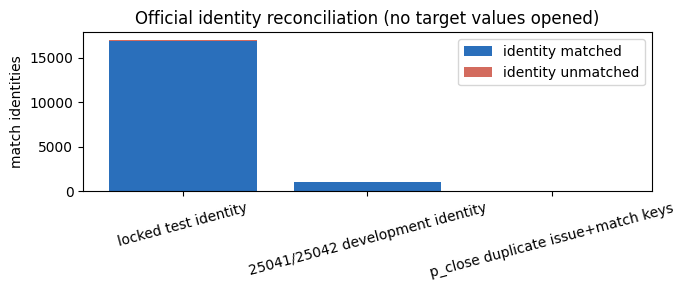

In [9]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(reconciliation.scope, reconciliation.matched, label='identity matched', color='#2a6fbb')
ax.bar(reconciliation.scope, reconciliation.unmatched, bottom=reconciliation.matched, label='identity unmatched', color='#d36b5e')
ax.tick_params(axis='x', rotation=15)
ax.set_ylabel('match identities')
ax.set_title('Official identity reconciliation (no target values opened)')
ax.legend()
fig.tight_layout()
plt.show()

In [10]:
schema = json.loads((PACKAGE / 'inference_schema.json').read_text())
assert schema['sp_target']['field'] == 'final_sp'
assert tuple(schema['sp_target']['outcome_axis']) == OUTCOME_ORDER
assert 'final_sp' not in schema['model_features']
assert schema['predicted_final_sp_semantics'] == 'outcome-unexposed pre-event proxy input only'
print('Target remains unopened:', schema['sp_target']['quality_mask'])

Target remains unopened: TARGET_ONLY_OFFICIAL_3SP_NOT_OPENED_GATE_A
